In [11]:
from typing import List, TypedDict
import time
from pydantic import BaseModel, Field
import re
from langchain_community.vectorstores import FAISS
from langchain.chat_models import init_chat_model
from langchain_community.embeddings import JinaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
import os

JINA_API_KEY = os.getenv("JINA_API_KEY")

embedder = JinaEmbeddings(

    jina_api_key=os.getenv("JINA_API_KEY"),

    model_name="jina-embeddings-v5-omni-nano"

)

In [3]:
# 2. Load existing FAISS database

vector_store = FAISS.load_local(

    "faiss_db",

    embeddings=embedder,

    allow_dangerous_deserialization=True

)
# 3. Create retriever
retriever = vector_store.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 4}
)

In [4]:
MODEL_NAME = "gemini-3.5-flash-lite"

model = init_chat_model(
    MODEL_NAME,
    model_provider="google_genai",
    temperature=0,
)

In [5]:
class State(TypedDict):

    question: str

    docs: List[Document]

    strips: List[str]

    kept_strips: List[str]

    refined_context: str

    answer: str

In [6]:
def retrieve(state: State) -> State:

    q = state["question"]

    # Retrieve documents from FAISS
    docs = retriever.invoke(q)

    return {
        "docs": docs
    }

In [8]:
# -----------------------------
# Sentence-level DECOMPOSER
# -----------------------------

def decompose_to_sentences(text: str) -> List[str]:

    text = re.sub(r"\s+", " ", text).strip()

    sentences = re.split(r"(?<=[.!?])\s+", text)

    return [
        s.strip()
        for s in sentences
        if len(s.strip()) > 20
    ]

In [9]:
decompose_to_sentences("""Transformers are a type of neural network architecture.

                       They use attention mechanisms to process information.

                        They are widely used in NLP applications.""")

['Transformers are a type of neural network architecture.',
 'They use attention mechanisms to process information.',
 'They are widely used in NLP applications.']

In [10]:
class RelevanceDecision(BaseModel):

    keep: bool = Field(
        description="True if the sentence directly helps answer the question, otherwise False."
    )

In [12]:
relevance_agent = create_agent(

    model=model,

    tools=[],

    response_format=RelevanceDecision,

    system_prompt="""

    You are a strict sentence-level relevance evaluator.

    Your task is to determine whether a given sentence
    directly helps answer the user's question.

    Rules:

    1. Evaluate only the provided sentence.
    2. Return keep=True only if the sentence directly
       contributes useful information to answering the question.
    3. Return keep=False if the sentence is unrelated,
       ambiguous, or discusses a different concept.
    4. Do not use external knowledge.
    5. Do not infer missing information from other sentences.

    """
)

In [13]:
# -----------------------------
# REFINEMENT NODE
# -----------------------------

def refine(state: State) -> State:

    q = state["question"]

    # Combine retrieved documents into one context string
    context = "\n\n".join(
        d.page_content for d in state["docs"]
    ).strip()

    # 1. DECOMPOSITION
    strips = decompose_to_sentences(context)

    # 2. FILTERING
    kept = []

    for sentence in strips:

        result = relevance_agent.invoke({

            "messages": [

                {
                    "role": "user",

                    "content": f"""
                    Question: {q}

                    Sentence:
                    {sentence}
                    """
                }

            ]

        })

        # Extract structured Boolean response
        decision = result["structured_response"]

        if decision.keep:

            kept.append(sentence)

    # 3. RECOMPOSITION
    refined_context = "\n".join(kept).strip()

    return {

        "strips": strips,

        "kept_strips": kept,

        "refined_context": refined_context

    }

In [23]:
answer_agent = create_agent(

    model=model,

    tools=[],

    system_prompt="""

    You are a helpful document-based question-answering assistant.

    Answer the user's question using ONLY the refined context.

    Follow these formatting instructions:

    1. Start with a clear introductory paragraph.
    2. Use appropriate Markdown headings (##).
    3. Use bullet points to explain important concepts.
    4. Highlight important terms using bold formatting.
    5. Keep paragraphs short and easy to understand.
    6. Use numbered lists when explaining steps or processes.
    7. Use mathematical equations in LaTeX when necessary.
    8. Maintain proper spacing between paragraphs and sections.
    9. Avoid unnecessarily long paragraphs.
    10. Do not repeat the same information.

    If the provided context is insufficient to answer
    the question, say:

    "I don't know based on the provided documents."

    Do not use external knowledge or invent information.

    Return the answer in clean Markdown format.

    """
)

In [24]:
# -----------------------------
# GENERATION NODE
# -----------------------------

def generate(state: State) -> State:

    q = state["question"]

    context = state["refined_context"]

    response = answer_agent.invoke({

        "messages": [

            {

                "role": "user",

                "content": f"""

                Question:
                {q}

                Refined Context:
                {context}

                Answer the question using only the refined context.

                """

            }

        ]

    })

    answer = response["messages"][-1].content

    return {

        "answer": answer

    }

In [25]:
# -----------------------------
# BUILD LANGGRAPH
# -----------------------------

workflow = StateGraph(State)

# Add nodes
workflow.add_node("retrieve", retrieve)

workflow.add_node("refine", refine)

workflow.add_node("generate", generate)


# Add edges
workflow.add_edge(START, "retrieve")

workflow.add_edge("retrieve", "refine")

workflow.add_edge("refine", "generate")

workflow.add_edge("generate", END)


# Compile graph
app = workflow.compile()

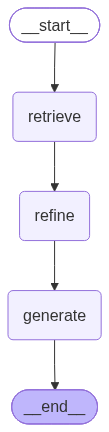

In [26]:
app

In [27]:

res = app.invoke({
    "question": "Explain the bias–variance tradeoff",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})
print(res["answer"])

/opt/anaconda3/envs/LandGraph/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/opt/anaconda3/envs/LandGraph/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/opt/anaconda3/envs/LandGraph/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/opt/anaconda3/envs/LandGraph/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the samplin

[{'type': 'text', 'text': 'The **bias-variance tradeoff** is a frequentist concept related to model complexity that helps determine the optimal predictive capability of a model by balancing two competing sources of error.\n\n## Decomposition of Expected Loss\n\nOur goal is to minimize the expected loss. The expected squared loss can be decomposed into the sum of three terms:\n\n$$\\text{expected loss} = (\\text{bias})^2 + \\text{variance} + \\text{noise}$$\n\n## Key Concepts of the Tradeoff\n\n* **Expected Loss Breakdown**: \n  * The **(squared) bias** represents the extent to which the average prediction over all data sets differs from the desired regression function.\n  * The **variance** measures the extent to which solutions for individual data sets vary around their average, showing how sensitive the function is to a particular choice of data set.\n  * The **noise** represents an irreducible constant term.\n\n* **Model Flexibility**:\n  * Very **flexible models** typically have **

In [28]:
from IPython.display import display, Markdown

answer = res["answer"]

if isinstance(answer, list):
    answer = answer[0]["text"]

display(Markdown(answer))

The **bias-variance tradeoff** is a frequentist concept related to model complexity that helps determine the optimal predictive capability of a model by balancing two competing sources of error.

## Decomposition of Expected Loss

Our goal is to minimize the expected loss. The expected squared loss can be decomposed into the sum of three terms:

$$\text{expected loss} = (\text{bias})^2 + \text{variance} + \text{noise}$$

## Key Concepts of the Tradeoff

* **Expected Loss Breakdown**: 
  * The **(squared) bias** represents the extent to which the average prediction over all data sets differs from the desired regression function.
  * The **variance** measures the extent to which solutions for individual data sets vary around their average, showing how sensitive the function is to a particular choice of data set.
  * The **noise** represents an irreducible constant term.

* **Model Flexibility**:
  * Very **flexible models** typically have **low bias** and **high variance**.
  * Relatively **rigid models** typically have **high bias** and **low variance**.

## Achieving Optimal Performance

To achieve the best predictive capability, follow these considerations:

1. Analyze the model complexity to find the point where **bias** and **variance** are balanced.
2. Minimize the expected loss by managing the tradeoff between the **(squared) bias** and the **variance**.

In [30]:
for i, doc in enumerate(res["docs"], 1):
    print(f"\nDocument {i}:")
    print(doc.page_content)
    print("-" * 100)


Document 1:
to consider a frequentist viewpoint of the model complexity issue, known as the bias-
variance trade-off. Although we shall introduce this concept in the context of linear
basis function models, where it is easy to illustrate the ideas using simple examples,
the discussion has more general applicability.
In Section 1.5.5, when we discussed decision theory for regression problems,
we considered various loss functions each of which leads to a corresponding optimal
prediction once we are given the conditional distribution p(t|x). A popular choice is
----------------------------------------------------------------------------------------------------

Document 2:
with respect to multiple data sets.
We can also examine the bias-variance trade-off quantitatively for this example.
The average prediction is estimated from
y(x)= 1 L
L∑
l=1
y(l)(x) (3.45)
and the integrated squared bias and integrated variance are then given by
(bias)2 = 1 N
N∑
n=1
{y(xn) − h(xn)}2 (3.46)
variance = 

In [32]:
for i, doc in enumerate(res["kept_strips"], 1):
    print(f"\nDocument {i}:")
    print(doc)
    print("-" * 100)


Document 1:
to consider a frequentist viewpoint of the model complexity issue, known as the bias- variance trade-off.
----------------------------------------------------------------------------------------------------

Document 2:
We can also examine the bias-variance trade-off quantitatively for this example.
----------------------------------------------------------------------------------------------------

Document 3:
The average prediction is estimated from y(x)= 1 L L∑ l=1 y(l)(x) (3.45) and the integrated squared bias and integrated variance are then given by (bias)2 = 1 N N∑ n=1 {y(xn) − h(xn)}2 (3.46) variance = 1 N N∑ n=1 1 L L∑ l=1 { y(l)(xn) − y(xn) }2 (3.47) where the integral over x weighted by the distribution p(x) is approximated by a ﬁnite sum over data points drawn from that distribution.
----------------------------------------------------------------------------------------------------

Document 4:
We see that small values of λ allow the model to become ﬁnely tune